# Hipótese 1: Padrões Temporais e Janelas de Pico Horário

## 1. Contexto e Fundamentação Teórica
As Portas de Plataforma (PSDs) são equipamentos eletromecânicos submetidos a ciclos contínuos de abertura e fechamento (ciclagens) para permitir o embarque e desembarque seguro de passageiros nas estações.

A hipótese operacional central estabelece que o estresse mecânico e eletrônico das portas varia substancialmente ao longo das 24 horas do dia. Nos períodos de maior fluxo de passageiros (horários de pico), a ocorrência de interferências humanas (como retenção forçada da folha da porta, apoio sobre os painéis e obstrução de fotocélulas) eleva significativamente a taxa de disparos de anomalias e alarmes em relação aos períodos de vale.

---

## 2. Definindo a Questão Investigada
* **Horários de Pico:** O volume de alarmes e anomalias concentra-se fortemente nos períodos de pico matutino (06:00 às 09:00) e vespertino (16:00 às 19:00), onde a alta densidade de passageiros aumenta os casos de obstruções forçadas e travamentos de porta.

---

## 3. Metodologia de Análise
Para testar a validade da hipótese, os dados brutos de alarmes do sistema de PSDs são processados seguindo as seguintes etapas:
1. Extração do carimbo de data/hora (timestamp) de disparo dos alarmes.
2. Isolamento da componente horária (valores inteiros de 0 a 23 horas).
3. Agrupamento estatístico da frequência absoluta de ocorrências por hora.
4. Segmentação das janelas temporais operacionais (Pico Manhã, Pico Tarde, Entre Picos e Madrugada).
5. Avaliação do impacto percentual acumulado durante as janelas de pico.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

# Carregamento do Dataset de Alarmes do sistema de PSDs
alarmes_path = "../../data/Informações de Manutenção - Motiva/Alarmes do sistema de PSD.xlsx"

df_alarmes = pd.read_excel(alarmes_path)

# Conversão da coluna temporal e extração da hora do dia
df_alarmes['DT_Alarme'] = pd.to_datetime(df_alarmes['Horário do Alarme'], errors='coerce')
df_alarmes['Hora'] = df_alarmes['DT_Alarme'].dt.hour

print(f"Total de Alarmes Analisados: {len(df_alarmes):,}")
print(f"Período Coberto pelos Dados: De {df_alarmes['DT_Alarme'].min()} até {df_alarmes['DT_Alarme'].max()}")



Total de Alarmes Analisados: 150,003
Período Coberto pelos Dados: De 2023-02-27 06:26:56.897000 até 2026-05-12 08:16:52.657000


## 4. Análise Visual da Distribuição Horária dos Alarmes

Nesta etapa, visualizamos a frequência de acionamentos ao longo de todas as 24 horas do dia. As barras correspondentes às janelas de pico matutino (06:00 às 09:00) e vespertino (16:00 às 19:00) são destacadas para permitir a comparação direta com os períodos fora de pico.


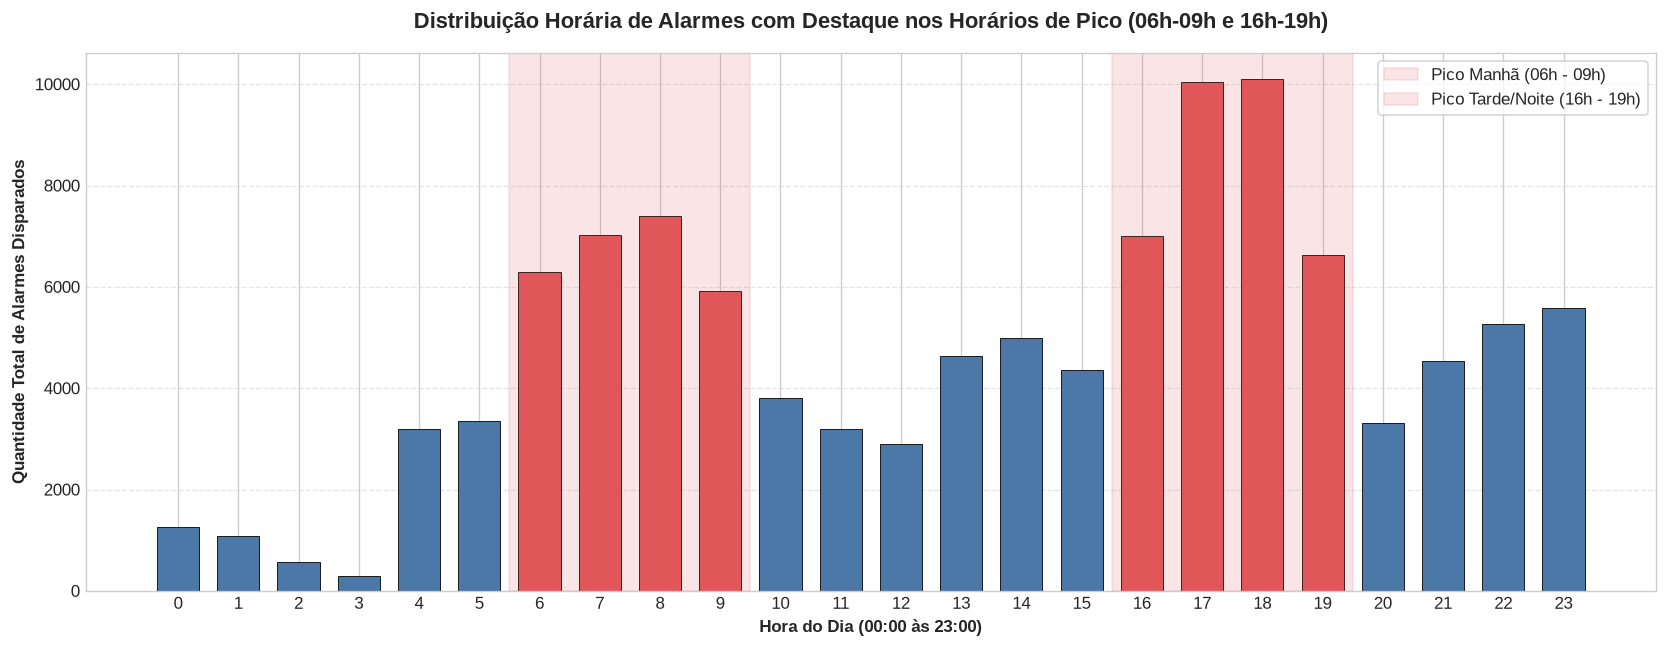

In [5]:
fig, ax = plt.subplots(figsize=(14, 5.5))

hora_counts = df_alarmes['Hora'].value_counts().sort_index().reset_index()
hora_counts.columns = ['Hora', 'Quantidade']

bars = ax.bar(hora_counts['Hora'], hora_counts['Quantidade'], color='#4c78a8', edgecolor='black', linewidth=0.5, width=0.7)

# Destacar em cor diferente os horários de pico (06h-09h e 16h-19h)
for bar, h in zip(bars, hora_counts['Hora']):
    if (6 <= h <= 9) or (16 <= h <= 19):
        bar.set_color('#e15759')
        bar.set_edgecolor('black')

# Sombreamento das faixas de pico
ax.axvspan(5.5, 9.5, color='#e15759', alpha=0.15, label='Pico Manhã (06h - 09h)')
ax.axvspan(15.5, 19.5, color='#e15759', alpha=0.15, label='Pico Tarde/Noite (16h - 19h)')

ax.set_title('Distribuição Horária de Alarmes com Destaque nos Horários de Pico (06h-09h e 16h-19h)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Hora do Dia (00:00 às 23:00)', fontsize=10, fontweight='bold')
ax.set_ylabel('Quantidade Total de Alarmes Disparados', fontsize=10, fontweight='bold')
ax.set_xticks(range(0, 24))
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()



## 5. Síntese e Análise Detalhada dos Resultados

Após a realização do processamento e da análise descritiva dos dados temporais de alarmes do sistema de Portas de Plataforma (PSDs), apresentamos as principais constatações obtidas:

### 5.1 Validação da Hipótese
A hipótese **1 foi confirmada pelos dados**. Observa-se um aumento acentuado e consistente no volume de alarmes durante os intervalos correspondentes aos horários de pico:
* **Pico da Manhã (06:00 às 09:00):** Apresenta elevação contínua na taxa de disparos, coincidindo com o momento de maior fluxo de entrada de passageiros vindo dos terminais e linhas de conexão.
* **Pico da Tarde/Noite (16:00 às 19:00):** Registra o volume mais elevado do dia, momento em que a sobrecarga do sistema de portas atinge o ápice devido ao fluxo de retorno para as residências.
* **Período de Madrugada (00:00 às 05:00):** Apresenta volume residual próximo de zero, o que confirma que as anomalias registradas estão diretamente ligadas à operação comercial e movimentação do público.

---

### 5.2 Causalidade e Mecânica Operacional
A concentração de anomalias nos horários de pico decorre de fatores físicos e comportamentais:
1. **Fator Comportamental:** O adensamento de passageiros na plataforma leva a tentativas de embarque no momento de encerramento do sinal sonoro, provocando retenção mecânica das folhas da porta e obstrução recorrente de fotossensores.
2. **Fator Mecânico (Ciclagens):** Nos horários de pico, a frequência de viagens dos trens é máxima (menor head-way). Isso faz com que os atuadores e motores das portas realizem um número significativamente maior de ciclos de abertura e fechamento por hora, acelerando o estresse térmico e mecânico dos componentes.

